# Part 1: Data Loading, Inspection & Cleaning
**Project:** Crime in India: Exploratory Data Analysis & Visualization
**Dataset:** NCRB district-wise crimes under the Indian Penal Code (IPC), from Kaggle `rajanand/crime-in-india`

**Steps in this notebook**
1. Load the CSV file(s)
2. Tidy the column names
3. Check data types
4. Check missing values
5. Check duplicates
6. Clean: standardize names and remove TOTAL rows
7. Detect outliers (IQR method)
8. Save the cleaned data

**Before running:** place the Kaggle IPC district-wise CSV file(s) in `data/raw/`.

## 0. Setup

In [18]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Folders (works whether you run from the notebooks/ folder or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
VISUALS_DIR = ROOT / "visuals"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)

Project folder: /Users/mantavyagupta/crime-in-india-analysis


## 1. Load the data
The district-wise IPC data is usually split into two files (for example 2001-2012 and 2013). The code loads every CSV in `data/raw/` whose name contains both `district` and `ipc`, tidies the column names, and stacks the files into one table.

Column names such as `STATE/UT` or `KIDNAPPING & ABDUCTION` are converted to lowercase with underscores (`state_ut`, `kidnapping_abduction`) *before* the files are joined, so small spelling or spacing differences between files do not split one column into two.

In [19]:
def tidy_names(columns):
    """'KIDNAPPING & ABDUCTION' -> 'kidnapping_abduction'"""
    return (
        pd.Index(columns).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
    )


matches = sorted(
    (p for p in RAW_DIR.rglob("*.csv")
     if "district" in p.name.lower() and "ipc" in p.name.lower()),
    key=lambda p: (len(p.parts), str(p)),      # shortest path first
)

# The same file can sit in two folders (e.g. data/raw/crime/ and data/raw/crime/crime/).
# Keep one copy of each file name so nothing is loaded twice.
csv_files, seen_names = [], set()
for p in matches:
    if p.name in seen_names:
        print("Skipping duplicate copy:", p.relative_to(ROOT))
        continue
    seen_names.add(p.name)
    csv_files.append(p)

if not csv_files:
    raise FileNotFoundError(
        f"No district-wise IPC CSV found in {RAW_DIR}. "
        "Put the Kaggle CSV file(s) in data/raw/ and run again."
    )

tables = []
for path in csv_files:
    try:
        part = pd.read_csv(path)
    except UnicodeDecodeError:
        part = pd.read_csv(path, encoding="latin-1")
    part.columns = tidy_names(part.columns)
    part["source_file"] = path.name          # remember where each row came from
    print(f"{path.name}: {part.shape[0]} rows, {part.shape[1]} columns")
    tables.append(part)

# Do all files have the same columns? Columns that exist in only some files will
# be empty (NaN) for the other files, so it is good to know about them.
all_columns = set().union(*[set(t.columns) for t in tables])
for path, t in zip(csv_files, tables):
    absent = sorted(all_columns - set(t.columns))
    if absent:
        print(f"\nNot present in {path.name}: {absent}")

df = pd.concat(tables, ignore_index=True)
rows_loaded = len(df)
print("\nCombined table:", df.shape)
df.head()

Skipping duplicate copy: data/raw/crime/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv
Skipping duplicate copy: data/raw/crime/crime/01_District_wise_crimes_committed_IPC_2013.csv
Skipping duplicate copy: data/raw/crime/crime/01_District_wise_crimes_committed_IPC_2014.csv
01_District_wise_crimes_committed_IPC_2001_2012.csv: 9017 rows, 34 columns
01_District_wise_crimes_committed_IPC_2013.csv: 823 rows, 34 columns
01_District_wise_crimes_committed_IPC_2014.csv: 838 rows, 92 columns

Not present in 01_District_wise_crimes_committed_IPC_2001_2012.csv: ['acid_attack', 'assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe', 'at_office_premises', 'attempt_to_acid_attack', 'attempt_to_commit_culpable_homicide', 'attempt_to_commit_murder', 'attempt_to_commit_rape', 'counterfeit_currency_bank_notes', 'counterfeit_offences_related_to_counterfeit_coin', 'counterfeiting', 'counterfeiting_currency_notes_bank_notes', 'counterfeiting_government_stamp', 'criminal_trespass_burgla

,state_ut,district,year,murder,attempt_to_murder,culpable_homicide_not_amounting_to_murder,rape,custodial_rape,other_rape,kidnapping_abduction,kidnapping_and_abduction_of_women_and_girls,kidnapping_and_abduction_of_others,dacoity,preparation_and_assembly_for_dacoity,robbery,burglary,theft,auto_theft,other_theft,riots,criminal_breach_of_trust,cheating,counterfieting,arson,hurt_grevious_hurt,...,sexual_harassment,assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,voyeurism,stalking,other_assault_on_women,insult_to_the_modesty_of_women,at_office_premises,other_places_related_to_work,in_public_transport_system,places_other_than_231_232_233,importation_of_girls_from_foreign_country,deaths_due_to_negligent_driving_act,deaths_due_to_other_causes,offences_against_state,sedition,other_offences_against_state,offences_promoting_enmity_between_different_groups,promoting_enmity_between_different_groups,imputation_assertions_prejudicial_to_national_integration,extortion,disclosure_of_identity_of_victims,incidence_of_rash_driving,humantrafficking,unnatural_offence,total_cognizable_ipc_crimes
0,ANDHRA PRADESH,ADILABAD,2001,101,60.0,17,50,0,50.0,46,30.0,16.0,9,0.0,41,198.0,199,22,177.0,78,16,104,1.0,30,1131.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125.0,1,23,0,23.0,53,30.0,23.0,8,0.0,16,191.0,366,57,309.0,168,11,65,8.0,69,1543.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ANDHRA PRADESH,CHITTOOR,2001,101,57.0,2,27,0,27.0,59,34.0,25.0,4,0.0,14,237.0,723,164,559.0,156,33,209,9.0,38,2088.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53.0,1,20,0,20.0,25,20.0,5.0,1,0.0,4,98.0,173,36,137.0,164,12,37,2.0,23,795.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67.0,1,23,0,23.0,49,26.0,23.0,4,0.0,25,437.0,1021,150,871.0,70,50,220,3.0,41,1244.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Check the key columns
`state_ut` is renamed to `state`. The notebook needs `state`, `district`, `year` and `total_ipc_crimes`. If one is missing, it stops and prints the columns it found, so you can see what is different.

In [20]:
df = df.rename(columns={"state_ut": "state"})

REQUIRED = ["state", "district", "year", "total_ipc_crimes"]
not_found = [c for c in REQUIRED if c not in df.columns]
if not_found:
    raise ValueError(f"Missing expected columns {not_found}. Columns found: {list(df.columns)}")

TOTAL_COL = "total_ipc_crimes"
CRIME_COLS = [c for c in df.columns if c not in ["state", "district", "year", "source_file"]]

print("Number of crime columns:", len(CRIME_COLS))
print(CRIME_COLS)

Number of crime columns: 101
['murder', 'attempt_to_murder', 'culpable_homicide_not_amounting_to_murder', 'rape', 'custodial_rape', 'other_rape', 'kidnapping_abduction', 'kidnapping_and_abduction_of_women_and_girls', 'kidnapping_and_abduction_of_others', 'dacoity', 'preparation_and_assembly_for_dacoity', 'robbery', 'burglary', 'theft', 'auto_theft', 'other_theft', 'riots', 'criminal_breach_of_trust', 'cheating', 'counterfieting', 'arson', 'hurt_grevious_hurt', 'dowry_deaths', 'assault_on_women_with_intent_to_outrage_her_modesty', 'insult_to_modesty_of_women', 'cruelty_by_husband_or_his_relatives', 'importation_of_girls_from_foreign_countries', 'causing_death_by_negligence', 'other_ipc_crimes', 'total_ipc_crimes', 'states_uts', 'attempt_to_commit_murder', 'attempt_to_commit_culpable_homicide', 'custodial_gang_rape', 'custodial_other_rape', 'rape_other_than_custodial', 'rape_gang_rape', 'rape_others', 'attempt_to_commit_rape', 'kidnapping_abduction_total', 'kidnapping_abduction_in_order_

## 3. Data types
Crime counts must be numbers and `year` must be a whole number. `pd.to_numeric(..., errors="coerce")` turns anything that is not a number into `NaN`, and we count how many values that affected.

In [21]:
print("Data types before conversion:")
print(df.dtypes.value_counts(), "\n")

nan_before = int(df[CRIME_COLS + ["year"]].isna().sum().sum())

for col in CRIME_COLS + ["year"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

nan_after = int(df[CRIME_COLS + ["year"]].isna().sum().sum())
print("Values that were not numbers and became NaN:", nan_after - nan_before)

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

print("\nYears covered:", df["year"].min(), "to", df["year"].max())
df.info()

Data types before conversion:
float64    82
int64      19
object      4
Name: count, dtype: int64 

Values that were not numbers and became NaN: 838

Years covered: 2001 to 2014
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10678 entries, 0 to 10677
Columns: 105 entries, state to total_cognizable_ipc_crimes
dtypes: float64(83), int64(19), object(3)
memory usage: 8.6+ MB


## 4. Missing values
We count missing values in every column. In this data a missing crime count means that nothing was reported, so those are filled with `0`. A row with no state or district cannot be placed anywhere, so it is dropped.

,missing_count,missing_percent
states_uts,10678,100.00
riots_students,9840,92.15
making_or_using_documents_resembling_currency,9840,92.15
voyeurism,9840,92.15
assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,9840,92.15
...,...,...
hurt_grevious_hurt,838,7.85
insult_to_modesty_of_women,838,7.85
importation_of_girls_from_foreign_countries,838,7.85
total_ipc_crimes,838,7.85


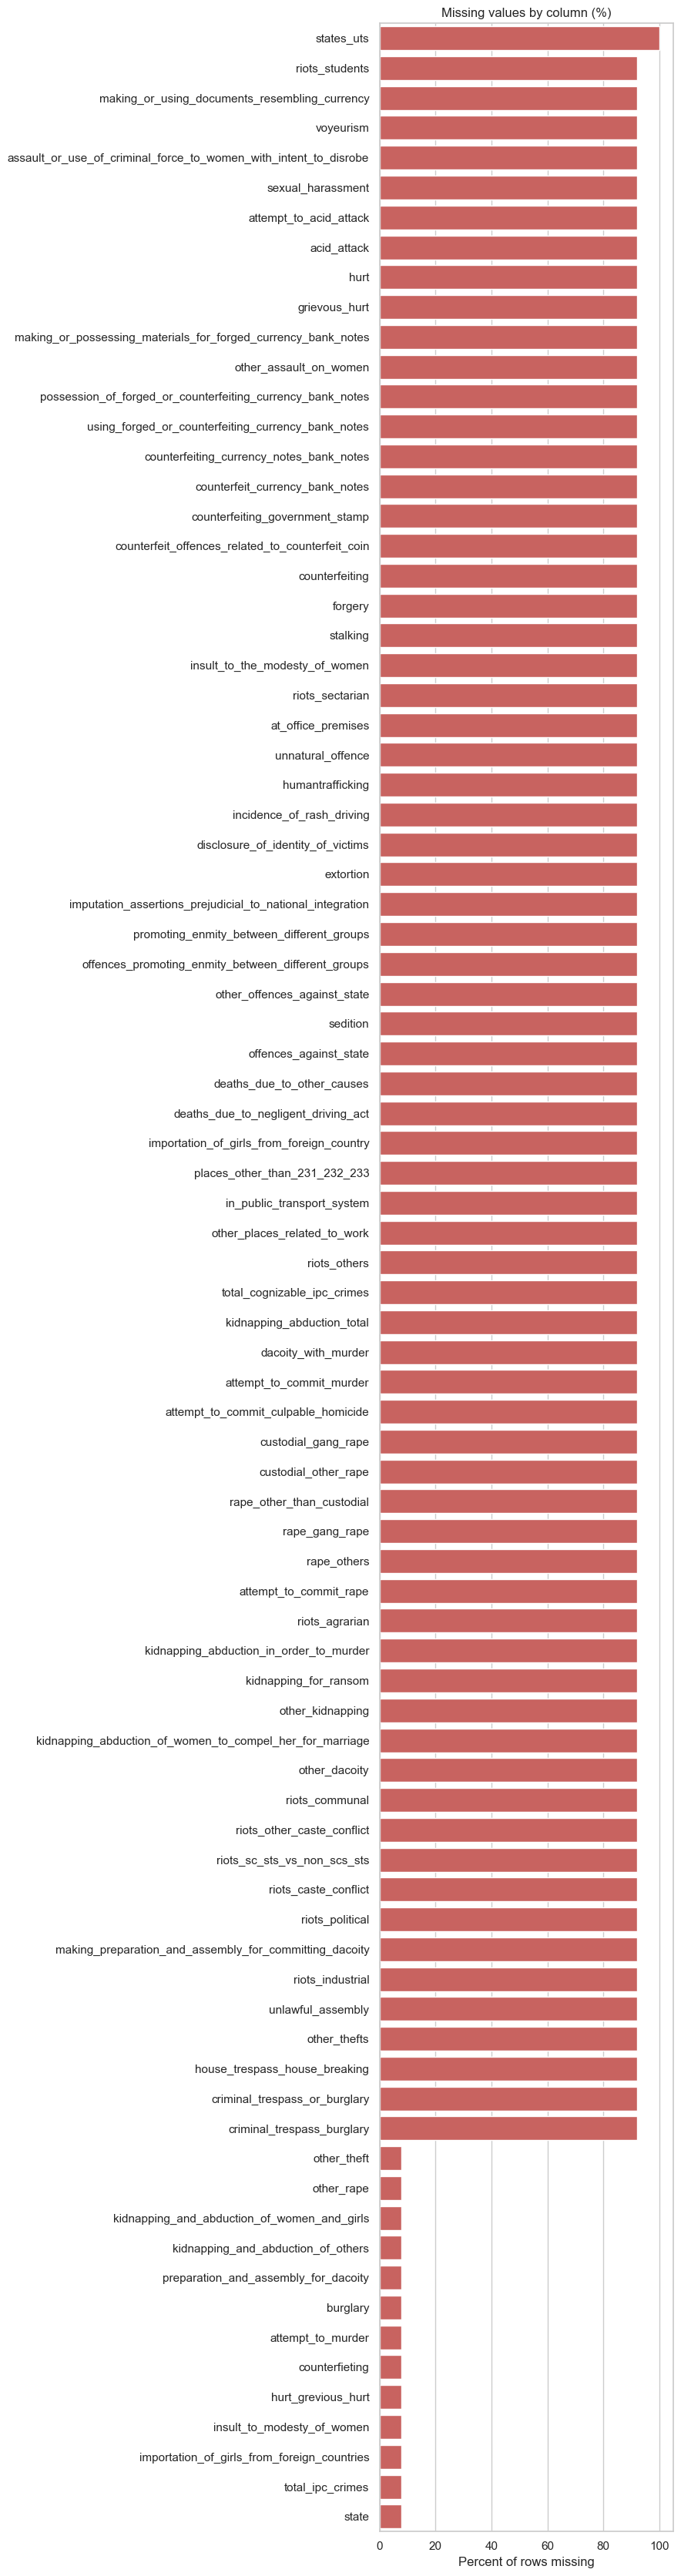

In [22]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    display(missing)
    fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(missing))))
    sns.barplot(x=missing["missing_percent"], y=missing.index, color="#d9534f", ax=ax)
    ax.set_title("Missing values by column (%)")
    ax.set_xlabel("Percent of rows missing")
    ax.set_ylabel("")
    plt.tight_layout()
    fig.savefig(VISUALS_DIR / "01_missing_values.png", dpi=150)
    plt.show()

In [23]:
rows_before = len(df)
df = df.dropna(subset=["state", "district"]).copy()
print("Rows dropped (no state or district):", rows_before - len(df))

filled = int(df[CRIME_COLS].isna().sum().sum())
df[CRIME_COLS] = df[CRIME_COLS].fillna(0)
print("Crime values filled with 0:", filled)

Rows dropped (no state or district): 838
Crime values filled with 0: 698640


## 5. Duplicates
Rows that are exactly the same twice would double count crimes, so they are removed. (`source_file` is ignored in this comparison.)

In [24]:
compare_cols = [c for c in df.columns if c != "source_file"]
print("Exact duplicate rows:", int(df.duplicated(subset=compare_cols).sum()))

df = df.drop_duplicates(subset=compare_cols).copy()
print("Rows remaining:", len(df))

Exact duplicate rows: 0
Rows remaining: 9840


## 6. Cleaning
### 6a. Standardize State/UT and district text
Spelling and spacing differ between files, and some states were renamed (Orissa is now Odisha). Everything is converted to upper case, extra spaces are removed, and old or variant state names are mapped to one name.

**Telangana (2014 data):** Telangana became a separate state in 2014. By default (`MERGE_TELANGANA = True`) it is counted inside Andhra Pradesh in every year. This keeps Andhra Pradesh comparable over time, and the map file used in Part 3 has no separate Telangana. Set it to `False` if you want Telangana on its own, and say so in your report.

In [25]:
for col in ["state", "district"]:
    df[col] = (
        df[col].astype(str).str.strip().str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

# Telangana was created from Andhra Pradesh in June 2014. If it is kept separate,
# Andhra Pradesh appears to "drop" in 2014 even though only its borders changed.
# True  = count Telangana inside Andhra Pradesh in every year (fair comparison over time).
# False = keep Telangana as its own state.
MERGE_TELANGANA = True

STATE_FIXES = {
    "A&N ISLANDS": "A & N ISLANDS",
    "ANDAMAN & NICOBAR ISLANDS": "A & N ISLANDS",
    "D&N HAVELI": "D & N HAVELI",
    "DADRA & NAGAR HAVELI": "D & N HAVELI",
    "DELHI UT": "DELHI",
    "ORISSA": "ODISHA",
    "CHATTISGARH": "CHHATTISGARH",
    "UTTARANCHAL": "UTTARAKHAND",
    "PONDICHERRY": "PUDUCHERRY",
}
if MERGE_TELANGANA:
    STATE_FIXES["TELANGANA"] = "ANDHRA PRADESH"

df["state"] = df["state"].replace(STATE_FIXES)
print("Done. Unique states/UTs so far:", df["state"].nunique())

Done. Unique states/UTs so far: 35


### 6b. Check and remove the TOTAL rows
The file contains summary rows such as a district called `TOTAL` (the state total) and an all-India total. If they stay, every crime is counted twice.

First a **sanity check**: for each state and year, does the official `TOTAL` row equal the sum of its districts? Then the TOTAL rows are removed.

In [26]:
is_total = df["district"].str.contains(r"\bTOTAL\b") | df["state"].str.contains(r"\bTOTAL\b")

official = df[df["district"] == "TOTAL"].groupby(["state", "year"])[TOTAL_COL].sum()
from_districts = df[~is_total].groupby(["state", "year"])[TOTAL_COL].sum()

check = pd.concat(
    [official.rename("official_total"), from_districts.rename("sum_of_districts")], axis=1
).dropna()
check["difference"] = check["official_total"] - check["sum_of_districts"]

n_bad = int((check["difference"] != 0).sum())
print(f"State-year combinations compared: {len(check)}")
print(f"Combinations where the official total differs from the district sum: {n_bad}")
if n_bad:
    display(check[check["difference"] != 0].head(10))

State-year combinations compared: 408
Combinations where the official total differs from the district sum: 0


In [27]:
print("TOTAL rows removed:", int(is_total.sum()))
df = df[~is_total].copy()

# Now the text can be made readable (Title Case) for charts and maps
df["state"] = df["state"].str.title()
df["district"] = df["district"].str.title()
print("Rows remaining:", len(df))

TOTAL rows removed: 455
Rows remaining: 9385


### 6c. Review state names and repeated district-years
Print the final list of states so you can spot any spelling variant that is still split in two. Also check that each state + district + year appears only once. If it appears more than once (for example the same district listed twice), the rows are added together.

In [28]:
states = sorted(df["state"].unique())
print(f"{len(states)} states/UTs:")
for s in states:
    print("  -", s)

35 states/UTs:
  - A & N Islands
  - Andhra Pradesh
  - Arunachal Pradesh
  - Assam
  - Bihar
  - Chandigarh
  - Chhattisgarh
  - D & N Haveli
  - Daman & Diu
  - Delhi
  - Goa
  - Gujarat
  - Haryana
  - Himachal Pradesh
  - Jammu & Kashmir
  - Jharkhand
  - Karnataka
  - Kerala
  - Lakshadweep
  - Madhya Pradesh
  - Maharashtra
  - Manipur
  - Meghalaya
  - Mizoram
  - Nagaland
  - Odisha
  - Puducherry
  - Punjab
  - Rajasthan
  - Sikkim
  - Tamil Nadu
  - Tripura
  - Uttar Pradesh
  - Uttarakhand
  - West Bengal


In [29]:
repeats = df.duplicated(subset=["state", "district", "year"], keep=False)
print("Rows sharing the same state + district + year:", int(repeats.sum()))

if repeats.any():
    display(df[repeats].sort_values(["state", "district", "year"]).head(10))
    df = df.groupby(["state", "district", "year"], as_index=False)[CRIME_COLS].sum()
    print("Repeated rows were added together. Rows now:", len(df))
else:
    df = df.drop(columns="source_file")

print("Negative crime values:", int((df[CRIME_COLS] < 0).sum().sum()))
df.head()

Rows sharing the same state + district + year: 2


,state,district,year,murder,attempt_to_murder,culpable_homicide_not_amounting_to_murder,rape,custodial_rape,other_rape,kidnapping_abduction,kidnapping_and_abduction_of_women_and_girls,kidnapping_and_abduction_of_others,dacoity,preparation_and_assembly_for_dacoity,robbery,burglary,theft,auto_theft,other_theft,riots,criminal_breach_of_trust,cheating,counterfieting,arson,hurt_grevious_hurt,...,sexual_harassment,assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,voyeurism,stalking,other_assault_on_women,insult_to_the_modesty_of_women,at_office_premises,other_places_related_to_work,in_public_transport_system,places_other_than_231_232_233,importation_of_girls_from_foreign_country,deaths_due_to_negligent_driving_act,deaths_due_to_other_causes,offences_against_state,sedition,other_offences_against_state,offences_promoting_enmity_between_different_groups,promoting_enmity_between_different_groups,imputation_assertions_prejudicial_to_national_integration,extortion,disclosure_of_identity_of_victims,incidence_of_rash_driving,humantrafficking,unnatural_offence,total_cognizable_ipc_crimes
6880,Jammu & Kashmir,Railways,2010,0,0.0,0,0,0,0.0,1,0.0,1.0,0,0.0,0,1.0,12,1,11.0,16,1,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6881,Jammu & Kashmir,Railways,2010,1,0.0,1,1,0,1.0,0,0.0,0.0,0,0.0,0,0.0,8,1,7.0,0,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Repeated rows were added together. Rows now: 9384
Negative crime values: 0


,state,district,year,murder,attempt_to_murder,culpable_homicide_not_amounting_to_murder,rape,custodial_rape,other_rape,kidnapping_abduction,kidnapping_and_abduction_of_women_and_girls,kidnapping_and_abduction_of_others,dacoity,preparation_and_assembly_for_dacoity,robbery,burglary,theft,auto_theft,other_theft,riots,criminal_breach_of_trust,cheating,counterfieting,arson,hurt_grevious_hurt,...,sexual_harassment,assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,voyeurism,stalking,other_assault_on_women,insult_to_the_modesty_of_women,at_office_premises,other_places_related_to_work,in_public_transport_system,places_other_than_231_232_233,importation_of_girls_from_foreign_country,deaths_due_to_negligent_driving_act,deaths_due_to_other_causes,offences_against_state,sedition,other_offences_against_state,offences_promoting_enmity_between_different_groups,promoting_enmity_between_different_groups,imputation_assertions_prejudicial_to_national_integration,extortion,disclosure_of_identity_of_victims,incidence_of_rash_driving,humantrafficking,unnatural_offence,total_cognizable_ipc_crimes
0,A & N Islands,A And N Islands,2007,15,19.0,1,3,0,3.0,12,9.0,3.0,5,0.0,9,90.0,112,8,104.0,17,7,23,1.0,11,99.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A & N Islands,Andaman,2001,13,0.0,0,3,0,3.0,2,2.0,0.0,0,0.0,4,62.0,65,4,61.0,13,10,8,2.0,4,113.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,A & N Islands,Andaman,2002,14,3.0,0,1,0,1.0,2,1.0,1.0,1,0.0,7,47.0,46,2,44.0,11,4,11,0.0,2,92.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A & N Islands,Andaman,2003,16,4.0,1,2,0,2.0,2,2.0,0.0,1,0.0,7,56.0,58,3,55.0,19,1,13,0.0,7,107.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,A & N Islands,Andaman,2004,13,1.0,2,10,0,10.0,3,3.0,0.0,0,0.0,3,67.0,100,9,91.0,9,0,11,0.0,8,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 7. Outliers (IQR method)
For each crime column: `IQR = Q3 - Q1`, and a value above `Q3 + 1.5 x IQR` is an outlier.

Crime counts are naturally skewed because big cities report far more cases, so these outliers are **real data, not errors**. They are measured and reported, but **not deleted**.

In [30]:
rows = []
for col in CRIME_COLS:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    upper_fence = q3 + 1.5 * (q3 - q1)
    n_outliers = int((df[col] > upper_fence).sum())
    rows.append({
        "crime": col,
        "upper_fence": round(upper_fence, 1),
        "outliers": n_outliers,
        "outlier_percent": round(n_outliers / len(df) * 100, 1),
        "max_value": df[col].max(),
    })

outlier_table = pd.DataFrame(rows).sort_values("outliers", ascending=False).reset_index(drop=True)
outlier_table.head(12)

,crime,upper_fence,outliers,outlier_percent,max_value
0,preparation_and_assembly_for_dacoity,5.0,1229,13.1,470.0
1,culpable_homicide_not_amounting_to_murder,12.5,1167,12.4,241.0
2,insult_to_modesty_of_women,30.0,1105,11.8,1257.0
3,auto_theft,312.0,955,10.2,7074.0
4,cheating,229.5,904,9.6,3155.0
5,counterfieting,7.5,881,9.4,217.0
6,dacoity,18.5,866,9.2,317.0
7,kidnapping_and_abduction_of_others,28.5,855,9.1,484.0
8,theft,956.0,820,8.7,13195.0
9,criminal_breach_of_trust,58.0,769,8.2,697.0


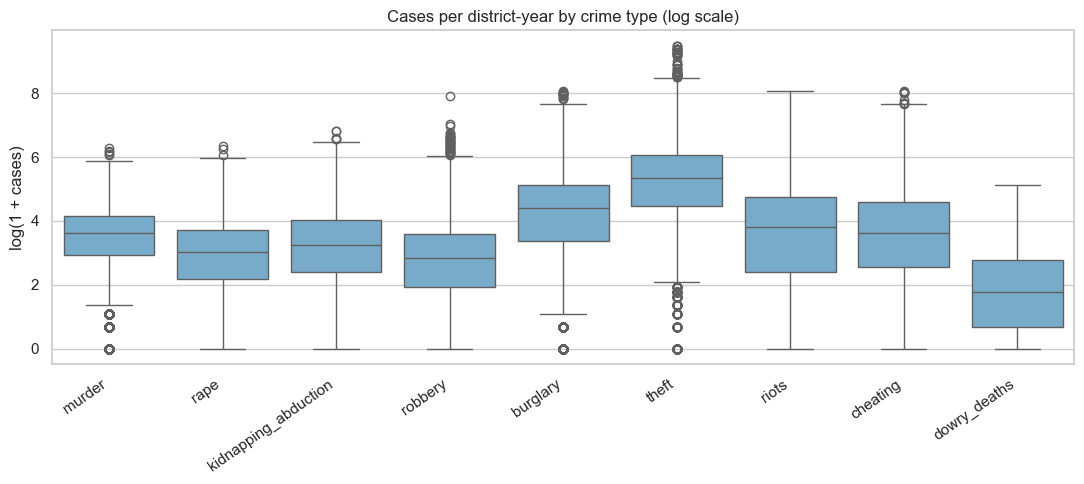

In [31]:
# Box plot for the main crime types. Log scale, because a few districts are huge.
MAIN_CRIMES = ["murder", "rape", "kidnapping_abduction", "robbery", "burglary",
               "theft", "riots", "cheating", "dowry_deaths"]
main = [c for c in MAIN_CRIMES if c in df.columns]

long_df = df[main].melt(var_name="crime", value_name="cases")
long_df["log_cases"] = np.log1p(long_df["cases"])

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=long_df, x="crime", y="log_cases", color="#6baed6", ax=ax)
ax.set_title("Cases per district-year by crime type (log scale)")
ax.set_xlabel("")
ax.set_ylabel("log(1 + cases)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
fig.savefig(VISUALS_DIR / "01_outliers_boxplot.png", dpi=150)
plt.show()

In [32]:
# The ten largest district-year records for total IPC crimes
df.nlargest(10, TOTAL_COL)[["state", "district", "year", TOTAL_COL]].reset_index(drop=True)

,state,district,year,total_ipc_crimes
0,Maharashtra,Mumbai Commr.,2013,34840.0
1,Kerala,Ernakulam Rural,2011,34638.0
2,Maharashtra,Mumbai Commr.,2010,33932.0
3,Maharashtra,Mumbai Commr.,2008,32770.0
4,Maharashtra,Mumbai Commr.,2011,32647.0
5,Karnataka,Bangalore Commr.,2009,32380.0
6,Karnataka,Bangalore Commr.,2010,32188.0
7,Maharashtra,Mumbai,2005,31432.0
8,Maharashtra,Mumbai Commr.,2009,31262.0
9,Maharashtra,Mumbai Commr.,2006,31070.0


**How to read this.** Large cities and districts appear at the top. They are kept because they genuinely have more reported crime. In Part 2 (EDA) we compare states using totals, and a per-lakh rate if population data is added later.

## 8. Save the cleaned data
Two files are saved for the next notebooks: one at district level and one with each state's yearly totals (used for trends, rankings and the map).

In [33]:
district_file = PROCESSED_DIR / "crime_ipc_district_clean.csv"
df.to_csv(district_file, index=False)

state_year = df.groupby(["state", "year"], as_index=False)[CRIME_COLS].sum()
state_file = PROCESSED_DIR / "crime_ipc_state_year.csv"
state_year.to_csv(state_file, index=False)

print("Saved:", district_file)
print("Saved:", state_file)
state_year.head()

Saved: /Users/mantavyagupta/crime-in-india-analysis/data/processed/crime_ipc_district_clean.csv
Saved: /Users/mantavyagupta/crime-in-india-analysis/data/processed/crime_ipc_state_year.csv


,state,year,murder,attempt_to_murder,culpable_homicide_not_amounting_to_murder,rape,custodial_rape,other_rape,kidnapping_abduction,kidnapping_and_abduction_of_women_and_girls,kidnapping_and_abduction_of_others,dacoity,preparation_and_assembly_for_dacoity,robbery,burglary,theft,auto_theft,other_theft,riots,criminal_breach_of_trust,cheating,counterfieting,arson,hurt_grevious_hurt,dowry_deaths,...,sexual_harassment,assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,voyeurism,stalking,other_assault_on_women,insult_to_the_modesty_of_women,at_office_premises,other_places_related_to_work,in_public_transport_system,places_other_than_231_232_233,importation_of_girls_from_foreign_country,deaths_due_to_negligent_driving_act,deaths_due_to_other_causes,offences_against_state,sedition,other_offences_against_state,offences_promoting_enmity_between_different_groups,promoting_enmity_between_different_groups,imputation_assertions_prejudicial_to_national_integration,extortion,disclosure_of_identity_of_victims,incidence_of_rash_driving,humantrafficking,unnatural_offence,total_cognizable_ipc_crimes
0,A & N Islands,2001,13,0.0,0,3,0,3.0,2,2.0,0.0,0,0.0,4,64.0,65,4,61.0,13,10,8,2.0,4,118.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A & N Islands,2002,17,3.0,1,2,0,2.0,2,1.0,1.0,1,0.0,7,49.0,49,2,47.0,11,4,11,0.0,2,97.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,A & N Islands,2003,21,4.0,1,2,0,2.0,2,2.0,0.0,2,0.0,7,56.0,60,3,57.0,19,3,13,0.0,8,110.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A & N Islands,2004,15,1.0,2,10,0,10.0,3,3.0,0.0,0,0.0,3,69.0,103,9,94.0,9,0,12,0.0,9,105.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,A & N Islands,2005,14,3.0,3,4,0,4.0,2,1.0,1.0,0,0.0,4,68.0,92,6,86.0,4,8,13,0.0,6,79.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
print("Rows loaded          :", rows_loaded)
print("Rows after cleaning  :", len(df))
print("Years                :", df["year"].min(), "-", df["year"].max())
print("States / UTs         :", df["state"].nunique())
print("Districts            :", df["district"].nunique())
print("Missing values left  :", int(df.isna().sum().sum()))
print("Exact duplicates left:", int(df.duplicated().sum()))

Rows loaded          : 10678
Rows after cleaning  : 9384
Years                : 2001 - 2013
States / UTs         : 35
Districts            : 825
Missing values left  : 0
Exact duplicates left: 0


## Summary
| Step | What was done |
|---|---|
| Load | CSV files combined into one table |
| Column names | lowercase with underscores |
| Data types | crime columns numeric, year integer |
| Missing values | counted, charted, crime counts filled with 0 |
| Duplicates | exact duplicates removed, repeated district-years added together |
| Cleaning | text standardized, TOTAL rows checked then removed |
| Outliers | measured with IQR and kept |
| Output | two cleaned CSV files in `data/processed/` |

**Next:** `02_eda_statistics.ipynb` (summary statistics and correlation).